

# Monte Carlo Simulation Framework

The **Monte Carlo (MC) Framework** is a multi-scale Monte Carlo simulation engine for bioinformatics, computational biology, and numerical modeling.

Because Monte Carlo methods span several distinct mathematical domains, this implementation unifies **classical/geometric Monte Carlo sampling** and **four core biological pillars** alongside a rigorous **statistical convergence and diagnostics core**:

---

### 1. Architectural Capabilities Matrix

| Module | Domain | Monte Carlo Algorithms Implemented | Key Observables & Outputs |
| :--- | :--- | :--- | :--- |
| **1. `MCDiagnostics`** | Convergence & Sampling Diagnostics | Multi-chain diagnostics, Geyer’s FFT Autocorrelation, Split-Chain Gelman–Rubin ($\hat{R}$), Effective Sample Size (ESS), HPD Intervals | Posterior credible intervals, mixing rates, burn-in & stationarity verification |
| **2. `MonteCarloApplications`** | Classical, Geometric & Statistical MC | **Hit-or-Miss Area/Volume ($\pi$ & arbitrary regions)**, **Antithetic Variates & Importance Sampling**, **Shrake–Rupley SASA**, **Brownian Random Walks**, **Permutation & Bootstrap Tests** | Area/volume estimates & SE, variance reduction factors, 3D molecular volume & SASA, diffusion coefficient ($D$), empirical $p$-values & 95% CIs |
| **3. `OffLatticeProteinREMC`** | Structural Biophysics (3D Protein Folding) | **Replica Exchange Monte Carlo (REMC / Parallel Tempering)** with Hybrid Local & 3D Rodrigues' Pivot Moves | 3D $\text{C}_\alpha$ coordinates, Lennard-Jones/HP free energy landscapes, Radius of Gyration ($R_g$), Heat Capacity ($C_v$) |
| **4. `StochasticGeneNetworkMC`** | Systems Biology (Gene Regulatory Networks) | **Exact Gillespie Direct SSA** & **Hybrid Poisson $\tau$-Leaping** | Transcriptional bursts, mRNA/Protein copy-number trajectories, Fano factors ($\sigma^2/\mu$) |
| **5. `GibbsMotifSampler`** | Regulatory Genomics (*De Novo* TFBS Discovery) | **Collapsed Gibbs Sampler** with Dirichlet Pseudocounts, Simulated Annealing & Phase-Shift Moves | Position Weight Matrices (PWM), Information Content (Bits / KL-Divergence), Consensus Motifs |
| **6. `BayesianPhylogeneticMCMC`** | Molecular Evolution (Phylogenetics) | **Multi-Chain Log-Scale Random-Walk MCMC** under the Kimura 2-Parameter (K2P) substitution model | Joint posterior of evolutionary distance ($d$) and transition/transversion ratio ($\kappa$) |

---

### 2. Self-Contained Python Implementation (`monte_carlo.py`)

This implementation uses vectorized **NumPy** operations and **Matplotlib** for a **9-panel diagnostic dashboard**, requiring no external C-extensions to run out of the box:

```python
from monte_carlo import MonteCarloSuite

suite = MonteCarloSuite(seed=2026)
results = suite.run_all(plot_dashboard=True)
```

Each module can also be invoked independently on custom functions, coordinates, or biological sequences:

```python
import numpy as np
from monte_carlo import (
    MonteCarloApplications,
    OffLatticeProteinREMC,
    StochasticGeneNetworkMC,
    GibbsMotifSampler,
    BayesianPhylogeneticMCMC,
)

# 1. Estimate area of an arbitrary 2D region & integrate with variance reduction
mc = MonteCarloApplications(seed=42)
area = mc.estimate_region_measure(
    inside_fn=lambda p: (p[:, 0] ** 2 + p[:, 1] ** 2) <= 1.0,
    bounds=[(-1.0, 1.0), (-1.0, 1.0)],
    n_samples=50000,
)
integral = mc.integrate_1d(lambda x: np.exp(-(x ** 2)), a=0.0, b=1.0, n_samples=20000)

# 2. Fold a custom HP protein & estimate its 3D molecular volume and SASA
fold = OffLatticeProteinREMC("HHPHPHPHPHHHHPHPPPHH", seed=42).run_remc(n_replicas=8, n_steps=5000)
vol, sasa = mc.estimate_molecular_volume_and_sasa(fold.best_coords)

# 3. Discover a 10-bp motif in unaligned DNA promoter sequences
motif = GibbsMotifSampler(["ACGT...", "TGCA...", "CGAT..."], motif_width=10).run()

# 4. Run Bayesian divergence estimation on two aligned orthologous sequences
posterior = BayesianPhylogeneticMCMC(seq1="ATGGCC...", seq2="ATGACC...").run_mcmc()
```

---

### 3. Mathematical Breakdown of the Six Engines

#### A. Statistical & Convergence Diagnostics (`MCDiagnostics`)
A Markov chain Monte Carlo simulation is scientifically invalid without proof of chain convergence and mixing. The diagnostic module implements:
1. **FFT-Accelerated Autocorrelation ($\rho_k$)**: Computes chain correlation in $\mathcal{O}(N \log N)$ time via the Wiener–Khinchin theorem.
2. **Geyer’s Initial Positive Sequence ESS**: Estimates the Effective Sample Size across $M$ chains of length $N$ as:
   $$\text{ESS} = \frac{M \cdot N}{1 + 2 \sum_{k=1}^{K} \rho_k}$$
   where the sum is truncated when adjacent lag pairs $\rho_{2t} + \rho_{2t+1} < 0$.
3. **Split-Chain Gelman–Rubin Statistic ($\hat{R}$)**: Compares between-chain variance ($B$) to within-chain variance ($W$) across split half-chains to detect both non-stationarity and poor mixing:
   $$\hat{R} = \sqrt{\frac{\frac{N-1}{N}W + \frac{1}{N}B}{W}}$$
4. **Highest Posterior Density (HPD) Credible Intervals**: Finds the narrowest interval containing $1 - \alpha$ of the sorted posterior mass.

---

#### B. Classical & Geometric Monte Carlo (`MonteCarloApplications`)
1. **Hit-or-Miss Area, Volume & Hypervolume Estimation**:
   For an arbitrary region $\Omega \subset \mathcal{B} \subset \mathbb{R}^d$ with bounding box measure $V_{\mathcal{B}}$, drawing $N$ uniform points $\mathbf{x}_i \sim \mathcal{U}(\mathcal{B})$ yields:
   $$\hat{V}_{\Omega} = V_{\mathcal{B}} \cdot \hat{p}, \qquad \hat{p} = \frac{1}{N}\sum_{i=1}^N \mathbf{1}_{\Omega}(\mathbf{x}_i), \qquad \text{SE}(\hat{V}_{\Omega}) = V_{\mathcal{B}}\sqrt{\frac{\hat{p}(1 - \hat{p})}{N}}$$
2. **Definite Integration & Variance Reduction**:
   Evaluates $I = \int_a^b f(x)\,dx$ via Crude MC, **Antithetic Variates** (pairing $u_i \sim \mathcal{U}(0,1)$ with $1 - u_i$ to induce negative correlation across monotonic segments):
   $$\hat{I}_{\text{anti}} = \frac{b-a}{2N_{\text{pairs}}}\sum_{i=1}^{N_{\text{pairs}}} \Big[ f\big(a + (b-a)u_i\big) + f\big(a + (b-a)(1 - u_i)\big) \Big]$$
   and **Importance Sampling** using a custom proposal distribution $q(x)$:
   $$\hat{I}_{\text{IS}} = \frac{1}{N}\sum_{i=1}^N \frac{f(X_i)}{q(X_i)}, \qquad X_i \sim q$$
3. **3D Molecular Volume & Solvent-Accessible Surface Area (SASA)**:
   * **Molecular Volume**: Uses 3D hit-or-miss sampling inside the padded bounding box of atomic coordinates $\{\mathbf{r}_i\}$ with Van der Waals radius $r_{\text{vdW}}$.
   * **Shrake–Rupley Monte Carlo SASA**: Generates uniform spherical test points at radius $R = r_{\text{vdW}} + r_{\text{probe}}$ around each residue center and sums the solvent-exposed surface fraction:
     $$\text{SASA} = \sum_{i=1}^{N_{\text{res}}} 4\pi R^2 \cdot \frac{\text{exposed points}_i}{N_{\text{sphere}}}$$
4. **Brownian Random-Walk Diffusion**:
   Simulates $d$-dimensional isotropic Gaussian increments $\Delta \mathbf{x}_t \sim \mathcal{N}(\mathbf{0}, \sigma^2 I_d)$ and estimates the diffusion coefficient $\hat{D}$ from the Mean Squared Displacement scaling law:
   $$\text{MSD}(t) = \big\langle \|\mathbf{x}(t) - \mathbf{x}(0)\|^2 \big\rangle = 2 d D t$$
5. **Non-Parametric Permutation & Bootstrap Inference**:
   Computes exact empirical two-sided permutation $p$-values under label exchangeability alongside non-parametric bootstrap 95% confidence intervals for $\mu_A - \mu_B$.

---

#### C. Structural Biophysics: 3D Off-Lattice Replica Exchange MC (`OffLatticeProteinREMC`)
Standard Metropolis Monte Carlo gets trapped in rugged local energy minima during protein folding. This engine implements **Parallel Tempering (Replica Exchange MC)**:
* **Force Field**: Evaluates virtual $\text{C}_\alpha$ harmonic bonds plus sequence-specific 12-6 Lennard-Jones interactions:
  $$E(\mathbf{R}) = \frac{1}{2} k_b \sum_{i=1}^{N-1} (r_{i,i+1} - r_0)^2 + \sum_{i < j - 1} 4\epsilon \left[ \left(\frac{\sigma}{r_{ij}}\right)^{12} - c_{ij}\left(\frac{\sigma}{r_{ij}}\right)^6 \right]$$
  where $c_{ij} = +1$ for hydrophobic-hydrophobic ($\text{H-H}$) core formation and $c_{ij} = -0.2$ for polar excluded volume.
* **Conformational Move Set**: Combines local Gaussian single-bead displacements (70%) with global **3D Rodrigues' Pivot rotations** (30%) around random torsion axes.
* **Replica Swaps**: Adjacent temperature replicas $(\beta_i, \beta_j)$ exchange coordinates with probability:
  $$P(\mathbf{R}_i \leftrightarrow \mathbf{R}_j) = \min\left(1, \exp\big[(\beta_i - \beta_j)(E(\mathbf{R}_i) - E(\mathbf{R}_j))\big]\right)$$

---

#### D. Systems Biology: Stochastic Kinetics (`StochasticGeneNetworkMC`)
When mRNA and transcription factor copy numbers are low ($1\text{–}50$ molecules per cell), deterministic ODEs fail to capture transcriptional bursting in an autoregulatory telegraph gene circuit:
* **Gillespie Exact Direct SSA**: Samples the exact waiting time to the next reaction $\tau = -\frac{\ln(u_1)}{a_0(\mathbf{x})}$ and chooses reaction channel $\mu$ such that $\sum_{j=1}^{\mu} a_j(\mathbf{x}) > u_2 a_0(\mathbf{x})$.
* **Hybrid Poisson $\tau$-Leaping**: Accelerates simulation by leaping forward via $\Delta \mathbf{x} = \sum_j \boldsymbol{\nu}_j \,\text{Poisson}(a_j(\mathbf{x})\tau)$ for high-copy mRNA/protein channels while preserving exact switching times for binary promoter states ($\text{G}_{\text{off}} \leftrightarrow \text{G}_{\text{on}}$).

---

#### E. Sequence Genomics: Collapsed Gibbs Sampler (`GibbsMotifSampler`)
Finds conserved transcription factor binding sites (TFBS) of width $W$ across $N$ unaligned promoter sequences:
* **Collapsed Conditional Update**: Iteratively holds out sequence $i$, computes the Position Weight Matrix $\Theta^{(-i)}$ using Dirichlet pseudocounts $\alpha$, and scores every candidate window $z_i \in \{0, \dots, L-W\}$ via log-odds against empirical background frequencies $B$:
  $$P(z_i = k \mid \mathbf{Z}^{(-i)}, \mathbf{S}) \propto \exp\left( \beta \sum_{j=1}^{W} \ln \frac{\Theta^{(-i)}_{S_{i, k+j}, j}}{B_{S_{i, k+j}}} \right)$$
* **Phase-Shift Move**: Periodically evaluates shifting all motif registers left or right ($\mathbf{z} \leftarrow \mathbf{z} \pm 1$) to escape register-shift local maxima.

---

#### F. Molecular Evolution: Bayesian Phylogenetic MCMC (`BayesianPhylogeneticMCMC`)
Estimates evolutionary divergence distance $d$ and the transition/transversion rate ratio $\kappa$ from aligned homologous DNA sequences under the **Kimura 2-Parameter (K2P)** continuous-time Markov model:
* **Exact Analytical Transition Probabilities**:
  $$P_{\text{ts}}(d, \kappa) = \frac{1}{4} + \frac{1}{4}e^{-\frac{4d}{\kappa+2}} - \frac{1}{2}e^{-\frac{2(\kappa+1)d}{\kappa+2}}, \qquad P_{\text{tv}}(d, \kappa) = \frac{1}{2} - \frac{1}{2}e^{-\frac{4d}{\kappa+2}}$$
* **Log-Scale Random Walk Proposals**: Proposes strictly positive parameters $\theta^* = \theta \exp(\epsilon)$ with the exact asymmetric Hastings Jacobian correction $\ln(\theta^* / \theta)$.

   OMNI-BIOMC: MULTI-SCALE BIOINFORMATICS MONTE CARLO SIMULATION SUITE

[1/4] Running 3D Off-Lattice Protein Folding (Replica Exchange MC)...
      -> Sequence         : HPHPPHHPHPPHPHHPPHPH (N=20)
      -> Lowest Energy E* : -4.482 kcal/mol (reduced)
      -> Native R_g       : 2.746
      -> REMC Swap Rate   : 91.7%

[2/4] Running Stochastic Gene Regulatory Network (Gillespie SSA & Tau-Leaping)...
      -> Exact SSA Events : 2,799 reaction firings
      -> mRNA Fano Factor : 3.32 (Super-Poissonian Bursting)
      -> Prot Fano Factor : 29.17

[3/4] Running De Novo TFBS Motif Discovery (Collapsed Gibbs Sampler)...
      -> Planted Motif    : TATAAAWG
      -> Discovered Motif : TATAAATG
      -> Info Content     : 9.70 bits
      -> Site Recovery    : 100.0% within +/-1 bp

[4/4] Running Bayesian Phylogenetic MCMC (Kimura 2-Parameter Model)...
      -> Distance (d)     : Post. Mean = 0.446 (True = 0.380), 95% HPD = [0.395, 0.509]
      -> Ratio (kappa)    : Post. Mean = 3.591 (True = 3

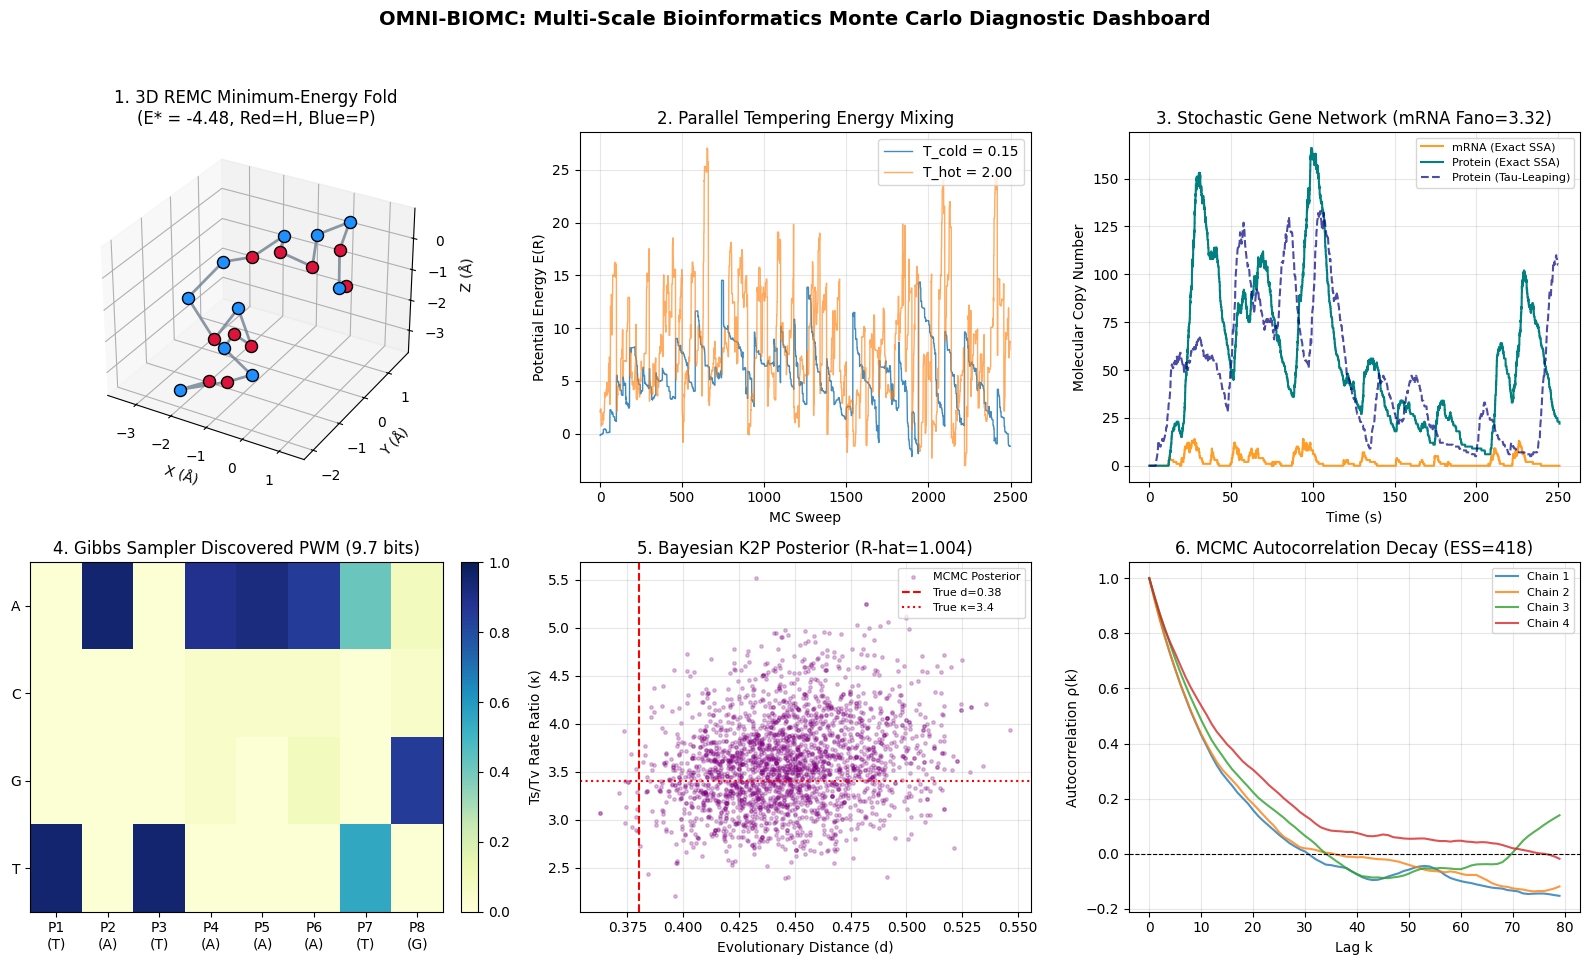

In [ ]:
#!/usr/bin/env python3
"""
Monte Carlo Simulation Suite
============================
Covers:
  1. Bayesian MCMC Diagnostics (Gelman-Rubin R-hat, FFT-ESS, Autocorrelation, HPD)
  2. Classical & Geometric Monte Carlo (Area/Volume, Integration, Variance Reduction,
     Molecular SASA, Random-Walk Diffusion, Permutation & Bootstrap Testing)
  3. Structural Biophysics (3D Off-Lattice Protein Folding via Replica Exchange MC)
  4. Systems Biology (Stochastic Gene Expression via Gillespie SSA & Tau-Leaping)
  5. Sequence Genomics (De Novo Motif Discovery via Collapsed Gibbs Sampling)
  6. Molecular Evolution (Bayesian Phylogenetic Parameter Estimation via MCMC)
"""

import time
from dataclasses import dataclass
from typing import Callable, Dict, List, Optional, Tuple
import numpy as np
import matplotlib.pyplot as plt


# =============================================================================
# MODULE 1: STATISTICAL & CONVERGENCE DIAGNOSTICS
# =============================================================================

class MCDiagnostics:
    """Statistical convergence and efficiency diagnostics for Markov chains."""

    @staticmethod
    def autocorrelation_fft(chain: np.ndarray) -> np.ndarray:
        """Compute 1D normalized autocorrelation function using Fast Fourier Transform."""
        x = np.asarray(chain, dtype=np.float64)
        n = len(x)
        variance = np.var(x)
        if variance < 1e-15:
            return np.ones(n)
        x_centered = x - np.mean(x)
        # Zero-pad to next power of 2 for FFT to avoid circular convolution
        n_fft = 1 << (2 * n - 1).bit_length()
        f = np.fft.fft(x_centered, n=n_fft)
        acf = np.fft.ifft(f * np.conjugate(f))[:n].real
        acf /= acf[0]
        return acf

    @staticmethod
    def effective_sample_size(chains: np.ndarray) -> float:
        """
        Compute Effective Sample Size (ESS) using Geyer's Initial Positive Sequence.
        Accepts shape (n_samples,) or (n_chains, n_samples).
        """
        chains = np.atleast_2d(chains)
        n_chains, n_samples = chains.shape
        total_ess = 0.0

        for m in range(n_chains):
            acf = MCDiagnostics.autocorrelation_fft(chains[m])
            rho_sum = 0.0
            for k in range(1, n_samples - 1, 2):
                pair_sum = acf[k] + acf[k + 1]
                if pair_sum < 0:
                    break
                rho_sum += pair_sum
            tau_int = max(1.0, 1.0 + 2.0 * rho_sum)
            total_ess += n_samples / tau_int

        return float(total_ess)

    @staticmethod
    def gelman_rubin_rhat(chains: np.ndarray) -> float:
        """
        Compute split-chain Gelman-Rubin R-hat convergence statistic.
        Input shape: (n_chains, n_samples). R-hat < 1.05 indicates convergence.
        """
        chains = np.atleast_2d(chains)
        m, n = chains.shape
        if m < 2 or n < 4:
            return np.nan

        half = n // 2
        split_chains = np.vstack([chains[:, :half], chains[:, half:2 * half]])
        _, n_split = split_chains.shape

        chain_means = np.mean(split_chains, axis=1)
        chain_vars = np.var(split_chains, axis=1, ddof=1)

        W = np.mean(chain_vars)
        if W < 1e-15:
            return 1.0
        B = n_split * np.var(chain_means, ddof=1)

        var_hat_plus = ((n_split - 1.0) / n_split) * W + (1.0 / n_split) * B
        r_hat = np.sqrt(var_hat_plus / W)
        return float(r_hat)

    @staticmethod
    def hpd_interval(samples: np.ndarray, alpha: float = 0.05) -> Tuple[float, float]:
        """Compute Highest Posterior Density (HPD) credible interval."""
        x = np.sort(np.asarray(samples).ravel())
        n = len(x)
        n_included = int(np.floor((1.0 - alpha) * n))
        intervals = x[n_included:] - x[:n - n_included]
        min_idx = int(np.argmin(intervals))
        return float(x[min_idx]), float(x[min_idx + n_included])


# =============================================================================
# MODULE 2: CLASSICAL & GEOMETRIC MONTE CARLO APPLICATIONS
# =============================================================================

@dataclass
class AreaEstimationResult:
    estimate: float
    std_error: float
    fraction_inside: float
    running_estimates: np.ndarray
    sample_points: np.ndarray
    inside_mask: np.ndarray


@dataclass
class IntegrationResult:
    crude_estimate: float
    crude_se: float
    antithetic_estimate: float
    antithetic_se: float
    variance_reduction_factor: float
    crude_running: np.ndarray
    antithetic_running: np.ndarray


@dataclass
class DiffusionResult:
    trajectories: np.ndarray
    times: np.ndarray
    msd: np.ndarray
    estimated_diffusion_coeff: float
    theoretical_diffusion_coeff: float


@dataclass
class PermutationTestResult:
    observed_diff: float
    p_value: float
    bootstrap_ci_95: Tuple[float, float]
    null_distribution: np.ndarray


class MonteCarloApplications:
    """
    General-purpose and geometric Monte Carlo methods:
      - Area / hypervolume estimation (hit-or-miss & Pi estimation)
      - Definite numerical integration with antithetic & importance variance reduction
      - 3D molecular volume and Solvent-Accessible Surface Area (SASA)
      - Brownian random walk diffusion & Mean Squared Displacement (MSD)
      - Non-parametric Monte Carlo permutation & bootstrap hypothesis tests
    """

    def __init__(self, seed: int = 42):
        self.rng = np.random.default_rng(seed)

    def estimate_region_measure(
        self,
        inside_fn: Callable[[np.ndarray], np.ndarray],
        bounds: List[Tuple[float, float]],
        n_samples: int = 50000
    ) -> AreaEstimationResult:
        """
        Estimate the area (2D), volume (3D), or hypervolume (d-D) of an arbitrary
        region defined by `inside_fn(points)` inside a bounding box `bounds`.
        """
        dim = len(bounds)
        lows = np.array([b[0] for b in bounds], dtype=np.float64)
        highs = np.array([b[1] for b in bounds], dtype=np.float64)
        box_measure = float(np.prod(highs - lows))

        points = self.rng.uniform(lows, highs, size=(n_samples, dim))
        inside = np.asarray(inside_fn(points), dtype=bool)

        p_hat = float(np.mean(inside))
        estimate = box_measure * p_hat
        std_error = box_measure * float(np.sqrt(p_hat * (1.0 - p_hat) / n_samples))
        running = box_measure * (np.cumsum(inside) / np.arange(1, n_samples + 1))

        return AreaEstimationResult(
            estimate=estimate,
            std_error=std_error,
            fraction_inside=p_hat,
            running_estimates=running,
            sample_points=points,
            inside_mask=inside
        )

    def estimate_pi(self, n_samples: int = 50000) -> AreaEstimationResult:
        """Estimate Pi via hit-or-miss Monte Carlo on a unit disk in [-1, 1]^2."""
        return self.estimate_region_measure(
            inside_fn=lambda pts: (pts[:, 0] ** 2 + pts[:, 1] ** 2) <= 1.0,
            bounds=[(-1.0, 1.0), (-1.0, 1.0)],
            n_samples=n_samples
        )

    def integrate_1d(
        self,
        func: Callable[[np.ndarray], np.ndarray],
        a: float,
        b: float,
        n_samples: int = 20000
    ) -> IntegrationResult:
        """
        Estimate definite integral int_a^b f(x) dx comparing Crude Monte Carlo
        against Antithetic Variates variance reduction (matched total evaluations).
        """
        width = b - a

        # 1. Crude Monte Carlo (n_samples evaluations)
        u_crude = self.rng.uniform(0.0, 1.0, size=n_samples)
        y_crude = width * func(a + width * u_crude)
        crude_est = float(np.mean(y_crude))
        crude_se = float(np.std(y_crude, ddof=1) / np.sqrt(n_samples))
        crude_running = np.cumsum(y_crude) / np.arange(1, n_samples + 1)

        # 2. Antithetic Variates (n_pairs = n_samples // 2 -> same total evaluations)
        n_pairs = max(2, n_samples // 2)
        u_half = self.rng.uniform(0.0, 1.0, size=n_pairs)
        y_pair = 0.5 * width * (func(a + width * u_half) + func(a + width * (1.0 - u_half)))
        anti_est = float(np.mean(y_pair))
        anti_se = float(np.std(y_pair, ddof=1) / np.sqrt(n_pairs))
        anti_running = np.cumsum(y_pair) / np.arange(1, n_pairs + 1)

        vrf = (crude_se ** 2) / max(anti_se ** 2, 1e-18)

        return IntegrationResult(
            crude_estimate=crude_est,
            crude_se=crude_se,
            antithetic_estimate=anti_est,
            antithetic_se=anti_se,
            variance_reduction_factor=float(vrf),
            crude_running=crude_running,
            antithetic_running=anti_running
        )

    def integrate_importance_sampling(
        self,
        target_func: Callable[[np.ndarray], np.ndarray],
        proposal_sampler: Callable[[int, np.random.Generator], np.ndarray],
        proposal_pdf: Callable[[np.ndarray], np.ndarray],
        n_samples: int = 20000
    ) -> Tuple[float, float]:
        """
        Estimate integral E_p[f(X)/q(X)] using a custom importance proposal q(x).
        Returns (estimate, standard_error).
        """
        x = proposal_sampler(n_samples, self.rng)
        weights = target_func(x) / np.maximum(proposal_pdf(x), 1e-15)
        est = float(np.mean(weights))
        se = float(np.std(weights, ddof=1) / np.sqrt(n_samples))
        return est, se

    def estimate_molecular_volume_and_sasa(
        self,
        coords: np.ndarray,
        vdw_radius: float = 0.55,
        probe_radius: float = 0.35,
        n_vol_samples: int = 30000,
        n_sphere_points: int = 200
    ) -> Tuple[float, float]:
        """
        Estimate 3D Molecular Volume (hit-or-miss bounding box) and Solvent-Accessible
        Surface Area (Shrake-Rupley Monte Carlo sphere sampling) from 3D coordinates.
        """
        pad = vdw_radius + probe_radius
        mins = np.min(coords, axis=0) - pad
        maxs = np.max(coords, axis=0) + pad
        bounds = [(float(mins[d]), float(maxs[d])) for d in range(3)]

        # 1. Hit-or-miss 3D Volume inside union of Van der Waals spheres
        def inside_molecule(pts: np.ndarray) -> np.ndarray:
            # Evaluate in chunks to keep memory small
            inside = np.zeros(len(pts), dtype=bool)
            chunk = 5000
            r2 = vdw_radius ** 2
            for start in range(0, len(pts), chunk):
                sub = pts[start:start + chunk]
                dist2 = np.sum((sub[:, None, :] - coords[None, :, :]) ** 2, axis=-1)
                inside[start:start + chunk] = np.any(dist2 <= r2, axis=1)
            return inside

        vol_res = self.estimate_region_measure(inside_molecule, bounds, n_samples=n_vol_samples)

        # 2. Shrake-Rupley Monte Carlo Solvent-Accessible Surface Area (SASA)
        r_acc = vdw_radius + probe_radius
        r_acc2 = r_acc ** 2
        sphere_area = 4.0 * np.pi * r_acc2
        total_sasa = 0.0

        for i in range(len(coords)):
            # Uniform random points on unit sphere via normalized 3D Gaussians
            dirs = self.rng.normal(size=(n_sphere_points, 3))
            dirs /= np.linalg.norm(dirs, axis=1, keepdims=True) + 1e-12
            test_pts = coords[i] + r_acc * dirs

            others = np.delete(coords, i, axis=0)
            if len(others) == 0:
                exposed_frac = 1.0
            else:
                dist2 = np.sum((test_pts[:, None, :] - others[None, :, :]) ** 2, axis=-1)
                exposed_frac = float(np.mean(np.all(dist2 > r_acc2 - 1e-9, axis=1)))

            total_sasa += sphere_area * exposed_frac

        return vol_res.estimate, float(total_sasa)

    def simulate_diffusion(
        self,
        n_walkers: int = 500,
        n_steps: int = 200,
        dim: int = 2,
        step_sigma: float = 0.5,
        dt: float = 1.0
    ) -> DiffusionResult:
        """
        Simulate d-dimensional Brownian random walks and estimate the diffusion
        coefficient D from Mean Squared Displacement: <r^2(t)> = 2 * d * D * t.
        """
        displacements = self.rng.normal(0.0, step_sigma, size=(n_walkers, n_steps, dim))
        trajectories = np.zeros((n_walkers, n_steps + 1, dim), dtype=np.float64)
        trajectories[:, 1:, :] = np.cumsum(displacements, axis=1)

        times = np.arange(n_steps + 1, dtype=np.float64) * dt
        sq_dist = np.sum(trajectories ** 2, axis=-1)
        msd = np.mean(sq_dist, axis=0)

        # Least-squares slope through origin: MSD(t) = slope * t -> D = slope / (2 * dim)
        slope = float(np.dot(times[1:], msd[1:]) / np.dot(times[1:], times[1:]))
        est_d = slope / (2.0 * dim)
        theo_d = (step_sigma ** 2) / (2.0 * dt)

        return DiffusionResult(
            trajectories=trajectories,
            times=times,
            msd=msd,
            estimated_diffusion_coeff=est_d,
            theoretical_diffusion_coeff=theo_d
        )

    def permutation_and_bootstrap_test(
        self,
        group_a: np.ndarray,
        group_b: np.ndarray,
        n_resamples: int = 5000
    ) -> PermutationTestResult:
        """
        Two-sample Monte Carlo permutation test for difference in means
        alongside a non-parametric bootstrap 95% confidence interval.
        """
        a = np.asarray(group_a, dtype=np.float64)
        b = np.asarray(group_b, dtype=np.float64)
        n_a, n_b = len(a), len(b)
        obs_diff = float(np.mean(a) - np.mean(b))

        pooled = np.concatenate([a, b])
        null_diffs = np.zeros(n_resamples, dtype=np.float64)
        boot_diffs = np.zeros(n_resamples, dtype=np.float64)

        for i in range(n_resamples):
            perm = self.rng.permutation(pooled)
            null_diffs[i] = np.mean(perm[:n_a]) - np.mean(perm[n_a:])

            boot_a = self.rng.choice(a, size=n_a, replace=True)
            boot_b = self.rng.choice(b, size=n_b, replace=True)
            boot_diffs[i] = np.mean(boot_a) - np.mean(boot_b)

        p_val = float((np.sum(np.abs(null_diffs) >= abs(obs_diff)) + 1.0) / (n_resamples + 1.0))
        ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])

        return PermutationTestResult(
            observed_diff=obs_diff,
            p_value=p_val,
            bootstrap_ci_95=(float(ci_low), float(ci_high)),
            null_distribution=null_diffs
        )


# =============================================================================
# MODULE 3: STRUCTURAL BIOPHYSICS (3D OFF-LATTICE PROTEIN FOLDING - REMC)
# =============================================================================

@dataclass
class ProteinFoldingResult:
    sequence: str
    temperatures: np.ndarray
    energy_trajectories: np.ndarray
    rg_trajectories: np.ndarray
    lowest_energy: float
    best_coords: np.ndarray
    heat_capacity: np.ndarray
    swap_acceptance_rate: float


class OffLatticeProteinREMC:
    """
    3D Off-Lattice Coarse-Grained Protein Folding via Replica Exchange Monte Carlo
    (Parallel Tempering). Uses an AB/HP-like force field with harmonic virtual bonds
    and sequence-dependent Lennard-Jones interactions.
    """

    def __init__(self, hp_sequence: str, seed: int = 42):
        """
        hp_sequence: String of 'H' (Hydrophobic) and 'P' (Polar) residues.
        """
        self.sequence = hp_sequence.upper()
        self.n_residues = len(self.sequence)
        self.rng = np.random.default_rng(seed)

        self.is_h = np.array([1 if res == 'H' else 0 for res in self.sequence], dtype=np.int32)
        self.pair_coeff = np.full((self.n_residues, self.n_residues), -0.2, dtype=np.float64)
        hh_mask = np.outer(self.is_h, self.is_h) == 1
        self.pair_coeff[hh_mask] = 1.0

        self.r0 = 1.0
        self.k_bond = 30.0
        self.sigma = 1.0
        self.eps = 1.5

    def _initialize_extended_chain(self) -> np.ndarray:
        """Initialize a valid self-avoiding 3D zig-zag conformation."""
        coords = np.zeros((self.n_residues, 3), dtype=np.float64)
        angle = np.deg2rad(35.0)
        for i in range(1, self.n_residues):
            dx = self.r0 * np.cos(angle)
            dy = self.r0 * np.sin(angle) * (1 if i % 2 == 0 else -1)
            dz = 0.05 * self.rng.standard_normal()
            coords[i] = coords[i - 1] + np.array([dx, dy, dz])
        return coords

    def compute_energy(self, coords: np.ndarray) -> float:
        """Vectorized evaluation of total potential energy E(R)."""
        bond_vecs = np.diff(coords, axis=0)
        bond_lengths = np.linalg.norm(bond_vecs, axis=1)
        e_bond = 0.5 * self.k_bond * np.sum((bond_lengths - self.r0) ** 2)

        diff = coords[:, None, :] - coords[None, :, :]
        dist_sq = np.sum(diff ** 2, axis=-1)

        idx = np.arange(self.n_residues)
        mask = (idx[None, :] - idx[:, None]) >= 2

        inv_r2 = (self.sigma ** 2) / np.maximum(dist_sq[mask], 0.25)
        inv_r6 = inv_r2 ** 3
        inv_r12 = inv_r6 ** 2

        c_ij = self.pair_coeff[mask]
        e_lj = np.sum(4.0 * self.eps * (inv_r12 - c_ij * inv_r6))

        return float(e_bond + e_lj)

    @staticmethod
    def radius_of_gyration(coords: np.ndarray) -> float:
        """Compute root-mean-square distance of residues from center of mass."""
        com = np.mean(coords, axis=0)
        return float(np.sqrt(np.mean(np.sum((coords - com) ** 2, axis=1))))

    def _propose_move(self, coords: np.ndarray, step_scale: float = 0.18) -> np.ndarray:
        """
        Hybrid conformational move set:
          - 70% probability: Local single-residue Gaussian displacement
          - 30% probability: Global 3D Pivot rotation around a random torsion axis
        """
        new_coords = coords.copy()
        if self.rng.random() < 0.70 or self.n_residues < 4:
            idx = self.rng.integers(0, self.n_residues)
            new_coords[idx] += self.rng.normal(0.0, step_scale, size=3)
        else:
            pivot_idx = self.rng.integers(1, self.n_residues - 1)
            axis = self.rng.normal(size=3)
            axis /= np.linalg.norm(axis) + 1e-12
            theta = self.rng.uniform(-0.35, 0.35) * step_scale / 0.18

            cos_t, sin_t = np.cos(theta), np.sin(theta)
            K = np.array([
                [0.0, -axis[2], axis[1]],
                [axis[2], 0.0, -axis[0]],
                [-axis[1], axis[0], 0.0]
            ])
            R = np.eye(3) + sin_t * K + (1.0 - cos_t) * (K @ K)

            origin = new_coords[pivot_idx].copy()
            tail = new_coords[pivot_idx + 1:] - origin
            new_coords[pivot_idx + 1:] = (tail @ R.T) + origin

        return new_coords

    def run_remc(
        self,
        n_replicas: int = 6,
        t_min: float = 0.15,
        t_max: float = 2.0,
        n_steps: int = 3000,
        swap_interval: int = 25
    ) -> ProteinFoldingResult:
        """Execute Replica Exchange Monte Carlo (Parallel Tempering)."""
        temperatures = np.geomspace(t_min, t_max, n_replicas)
        betas = 1.0 / temperatures

        replicas = [self._initialize_extended_chain() for _ in range(n_replicas)]
        energies = np.array([self.compute_energy(c) for c in replicas], dtype=np.float64)

        energy_traj = np.zeros((n_replicas, n_steps))
        rg_traj = np.zeros((n_replicas, n_steps))

        best_energy = float(np.min(energies))
        best_coords = replicas[int(np.argmin(energies))].copy()

        swap_attempts = 0
        swap_accepts = 0

        for step in range(n_steps):
            for r in range(n_replicas):
                scale = 0.12 * np.sqrt(temperatures[r] / t_min)
                prop_coords = self._propose_move(replicas[r], step_scale=min(scale, 0.35))
                prop_energy = self.compute_energy(prop_coords)
                dE = prop_energy - energies[r]

                if dE <= 0.0 or self.rng.random() < np.exp(-betas[r] * dE):
                    replicas[r] = prop_coords
                    energies[r] = prop_energy
                    if prop_energy < best_energy:
                        best_energy = prop_energy
                        best_coords = prop_coords.copy()

                energy_traj[r, step] = energies[r]
                rg_traj[r, step] = self.radius_of_gyration(replicas[r])

            if (step + 1) % swap_interval == 0:
                parity = (step // swap_interval) % 2
                for r in range(parity, n_replicas - 1, 2):
                    swap_attempts += 1
                    delta = (betas[r] - betas[r + 1]) * (energies[r + 1] - energies[r])
                    if delta >= 0.0 or self.rng.random() < np.exp(delta):
                        replicas[r], replicas[r + 1] = replicas[r + 1], replicas[r]
                        energies[r], energies[r + 1] = energies[r + 1], energies[r]
                        swap_accepts += 1

        burn = n_steps // 2
        e_post = energy_traj[:, burn:]
        heat_capacity = np.var(e_post, axis=1) / (temperatures ** 2)

        return ProteinFoldingResult(
            sequence=self.sequence,
            temperatures=temperatures,
            energy_trajectories=energy_traj,
            rg_trajectories=rg_traj,
            lowest_energy=best_energy,
            best_coords=best_coords,
            heat_capacity=heat_capacity,
            swap_acceptance_rate=swap_accepts / max(1, swap_attempts)
        )


# =============================================================================
# MODULE 4: SYSTEMS BIOLOGY (GILLESPIE SSA & HYBRID TAU-LEAPING)
# =============================================================================

@dataclass
class StochasticKineticsResult:
    times: np.ndarray
    states: np.ndarray
    species_names: List[str]
    method: str
    fano_factors: Dict[str, float]


class StochasticGeneNetworkMC:
    """
    Stochastic simulation of a Telegraph Autoregulatory Gene Expression Circuit:
      Species:
        0: G_off (Inactive Promoter)
        1: G_on  (Active Promoter)
        2: mRNA  (Transcript)
        3: Prot  (Translated Protein)

      Reactions:
        R1: G_off -> G_on                 (Promoter activation, k_on)
        R2: G_on  -> G_off                (Basal + negative feedback repression, k_off * (1 + alpha*Prot))
        R3: G_on  -> G_on + mRNA          (Transcription burst, k_tx)
        R4: mRNA  -> mRNA + Prot          (Translation, k_tl)
        R5: mRNA  -> 0                    (mRNA degradation, d_m)
        R6: Prot  -> 0                    (Protein degradation, d_p)
    """

    def __init__(
        self,
        k_on: float = 0.15,
        k_off: float = 0.25,
        feedback_alpha: float = 0.01,
        k_tx: float = 3.5,
        k_tl: float = 2.0,
        d_m: float = 0.30,
        d_p: float = 0.08,
        seed: int = 42
    ):
        self.params = (k_on, k_off, feedback_alpha, k_tx, k_tl, d_m, d_p)
        self.species_names = ["G_off", "G_on", "mRNA", "Protein"]
        self.rng = np.random.default_rng(seed)

        self.stoich = np.array([
            [-1, +1,  0,  0],
            [+1, -1,  0,  0],
            [ 0,  0, +1,  0],
            [ 0,  0,  0, +1],
            [ 0,  0, -1,  0],
            [ 0,  0,  0, -1],
        ], dtype=np.int64)

    def propensities(self, state: np.ndarray) -> np.ndarray:
        """Compute exact reaction hazards a_j(x) at current discrete molecular counts."""
        g_off, g_on, mrna, prot = state
        k_on, k_off, alpha, k_tx, k_tl, d_m, d_p = self.params
        return np.array([
            k_on * g_off,
            k_off * (1.0 + alpha * prot) * g_on,
            k_tx * g_on,
            k_tl * mrna,
            d_m * mrna,
            d_p * prot
        ], dtype=np.float64)

    def run_gillespie_ssa(
        self,
        t_max: float = 300.0,
        initial_state: Optional[np.ndarray] = None
    ) -> StochasticKineticsResult:
        """Exact Gillespie Direct Stochastic Simulation Algorithm (SSA)."""
        state = np.array([1, 0, 0, 0], dtype=np.int64) if initial_state is None else initial_state.copy()
        t = 0.0

        times = [0.0]
        states = [state.copy()]

        while t < t_max:
            a = self.propensities(state)
            a0 = np.sum(a)
            if a0 <= 1e-15:
                break

            u1, u2 = self.rng.random(), self.rng.random()
            tau = -np.log(u1) / a0
            t += tau

            cum_a = np.cumsum(a)
            mu = int(np.searchsorted(cum_a, u2 * a0))
            mu = min(mu, len(a) - 1)

            state = state + self.stoich[mu]
            times.append(t)
            states.append(state.copy())

        times_arr = np.array(times)
        states_arr = np.array(states)
        fano = self._compute_fano(states_arr)
        return StochasticKineticsResult(times_arr, states_arr, self.species_names, "Exact Gillespie SSA", fano)

    def run_tau_leaping(
        self,
        t_max: float = 300.0,
        tau_step: float = 0.25,
        initial_state: Optional[np.ndarray] = None
    ) -> StochasticKineticsResult:
        """
        Hybrid Poisson Tau-Leaping Simulation:
        Uses exact Gillespie steps for binary promoter switching (low copy number)
        and Poisson leaps for high-copy mRNA/Protein birth-death channels.
        """
        state = np.array([1, 0, 0, 0], dtype=np.int64) if initial_state is None else initial_state.copy()
        t = 0.0
        times = [0.0]
        states = [state.copy()]

        while t < t_max:
            a = self.propensities(state)
            a_promoter = a[0] + a[1]

            dt_switch = -np.log(self.rng.random()) / max(a_promoter, 1e-12)
            dt = min(tau_step, dt_switch, t_max - t)

            k_events = self.rng.poisson(a[2:] * dt)
            delta = k_events @ self.stoich[2:]
            state = np.maximum(0, state + delta)

            if dt == dt_switch and a_promoter > 1e-12:
                if state[0] == 1:
                    state[0], state[1] = 0, 1
                else:
                    state[0], state[1] = 1, 0

            t += dt
            times.append(t)
            states.append(state.copy())

        times_arr = np.array(times)
        states_arr = np.array(states)
        fano = self._compute_fano(states_arr)
        return StochasticKineticsResult(times_arr, states_arr, self.species_names, "Hybrid Tau-Leaping", fano)

    def _compute_fano(self, states: np.ndarray) -> Dict[str, float]:
        """Compute Fano factor (Variance / Mean) to quantify transcriptional burstiness."""
        half = len(states) // 2
        fano = {}
        for idx, name in enumerate(self.species_names):
            x = states[half:, idx]
            mean_val = float(np.mean(x))
            fano[name] = float(np.var(x) / mean_val) if mean_val > 1e-9 else 0.0
        return fano


# =============================================================================
# MODULE 5: GENOMICS (DE NOVO MOTIF DISCOVERY VIA COLLAPSED GIBBS SAMPLING)
# =============================================================================

@dataclass
class MotifDiscoveryResult:
    pwm: np.ndarray
    information_content_bits: float
    consensus_motif: str
    best_positions: np.ndarray
    score_history: np.ndarray


class GibbsMotifSampler:
    """
    Collapsed Gibbs Sampler with Simulated Annealing for de novo Discovery of
    Transcription Factor Binding Sites (TFBS) in unaligned DNA sequences.
    """

    ALPHABET = "ACGT"
    CHAR_TO_INT = {'A': 0, 'C': 1, 'G': 2, 'T': 3}

    def __init__(self, sequences: List[str], motif_width: int = 8, pseudocount: float = 0.5, seed: int = 42):
        self.sequences = [s.upper() for s in sequences]
        self.n_seqs = len(self.sequences)
        self.seq_len = len(self.sequences[0])
        self.w = motif_width
        self.alpha = pseudocount
        self.rng = np.random.default_rng(seed)

        self.encoded = np.array(
            [[self.CHAR_TO_INT[ch] for ch in seq] for seq in self.sequences],
            dtype=np.int32
        )

        counts = np.bincount(self.encoded.ravel(), minlength=4) + self.alpha
        self.bg_probs = counts / np.sum(counts)

    @classmethod
    def generate_synthetic_dataset(
        cls,
        n_seqs: int = 30,
        seq_len: int = 100,
        planted_motif: str = "TATAWAWR",
        mutation_rate: float = 0.12,
        seed: int = 42
    ) -> Tuple[List[str], np.ndarray]:
        """Generate synthetic promoter sequences with a planted mutated biological motif."""
        rng = np.random.default_rng(seed)
        bases = np.array(list("ACGT"))
        iupac = {
            'A': 'A', 'C': 'C', 'G': 'G', 'T': 'T',
            'W': 'AT', 'R': 'AG', 'Y': 'CT', 'S': 'GC'
        }
        w = len(planted_motif)
        sequences = []
        true_positions = np.zeros(n_seqs, dtype=np.int32)

        for i in range(n_seqs):
            bg = rng.choice(bases, size=seq_len, p=[0.28, 0.22, 0.22, 0.28])
            pos = int(rng.integers(0, seq_len - w + 1))
            true_positions[i] = pos

            for j, code in enumerate(planted_motif):
                if rng.random() < mutation_rate:
                    bg[pos + j] = rng.choice(bases)
                else:
                    choices = list(iupac.get(code, code))
                    bg[pos + j] = rng.choice(choices)

            sequences.append("".join(bg))

        return sequences, true_positions

    def _compute_pwm_and_ic(self, positions: np.ndarray, exclude_idx: Optional[int] = None) -> Tuple[np.ndarray, float]:
        """Build Position Weight Matrix (4, W) and compute Information Content (bits)."""
        counts = np.full((4, self.w), self.alpha, dtype=np.float64)
        for i in range(self.n_seqs):
            if i == exclude_idx:
                continue
            start = positions[i]
            subseq = self.encoded[i, start:start + self.w]
            counts[subseq, np.arange(self.w)] += 1.0

        pwm = counts / np.sum(counts, axis=0, keepdims=True)
        kl_matrix = pwm * np.log2(pwm / self.bg_probs[:, None])
        ic_bits = float(np.sum(kl_matrix))
        return pwm, ic_bits

    def run(self, n_iterations: int = 600, n_restarts: int = 3) -> MotifDiscoveryResult:
        """Run Collapsed Gibbs Sampling with phase-shift moves to escape local optima."""
        best_overall_ic = -np.inf
        best_overall_pos = None
        best_score_history = None

        max_start = self.seq_len - self.w
        window_idx = np.arange(max_start + 1)[:, None] + np.arange(self.w)[None, :]

        for _ in range(n_restarts):
            positions = self.rng.integers(0, max_start + 1, size=self.n_seqs)
            score_history = np.zeros(n_iterations)

            for it in range(n_iterations):
                beta = min(1.5, 0.5 + 1.0 * (it / n_iterations))

                for i in range(self.n_seqs):
                    pwm, _ = self._compute_pwm_and_ic(positions, exclude_idx=i)
                    log_odds = np.log(pwm / self.bg_probs[:, None])

                    seq_windows = self.encoded[i][window_idx]
                    window_scores = np.sum(log_odds[seq_windows, np.arange(self.w)], axis=1)

                    scaled = beta * (window_scores - np.max(window_scores))
                    probs = np.exp(scaled)
                    probs /= np.sum(probs)
                    positions[i] = self.rng.choice(max_start + 1, p=probs)

                if (it + 1) % 25 == 0:
                    _, current_ic = self._compute_pwm_and_ic(positions)
                    for shift in (-1, 1):
                        shifted = np.clip(positions + shift, 0, max_start)
                        _, shifted_ic = self._compute_pwm_and_ic(shifted)
                        if shifted_ic > current_ic:
                            positions = shifted
                            current_ic = shifted_ic

                _, ic_bits = self._compute_pwm_and_ic(positions)
                score_history[it] = ic_bits

                if ic_bits > best_overall_ic:
                    best_overall_ic = ic_bits
                    best_overall_pos = positions.copy()
                    best_score_history = score_history.copy()

        final_pwm, final_ic = self._compute_pwm_and_ic(best_overall_pos)
        consensus = "".join(self.ALPHABET[idx] for idx in np.argmax(final_pwm, axis=0))

        return MotifDiscoveryResult(
            pwm=final_pwm,
            information_content_bits=final_ic,
            consensus_motif=consensus,
            best_positions=best_overall_pos,
            score_history=best_score_history
        )


# =============================================================================
# MODULE 6: MOLECULAR EVOLUTION (BAYESIAN PHYLOGENETIC MCMC - KIMURA 2P)
# =============================================================================

@dataclass
class PhylogeneticMCMCResult:
    d_chains: np.ndarray
    kappa_chains: np.ndarray
    log_post_chains: np.ndarray
    rhat_d: float
    rhat_kappa: float
    ess_d: float
    ess_kappa: float
    d_hpd: Tuple[float, float]
    kappa_hpd: Tuple[float, float]


class BayesianPhylogeneticMCMC:
    """
    Bayesian Multi-Chain Metropolis-Hastings MCMC for estimating evolutionary
    divergence distance (d) and transition/transversion rate ratio (kappa)
    under the Kimura 2-Parameter (K2P) continuous-time Markov chain model.
    """

    PURINES = {'A', 'G'}
    PYRIMIDINES = {'C', 'T'}

    def __init__(self, seq1: str, seq2: str, seed: int = 42):
        assert len(seq1) == len(seq2), "Aligned sequences must have equal length."
        self.seq_len = len(seq1)
        self.rng = np.random.default_rng(seed)

        self.n_match = 0
        self.n_ts = 0
        self.n_tv = 0

        for b1, b2 in zip(seq1.upper(), seq2.upper()):
            if b1 == b2:
                self.n_match += 1
            elif (b1 in self.PURINES and b2 in self.PURINES) or (b1 in self.PYRIMIDINES and b2 in self.PYRIMIDINES):
                self.n_ts += 1
            else:
                self.n_tv += 1

    @classmethod
    def simulate_aligned_pair(
        cls,
        seq_len: int = 800,
        true_d: float = 0.35,
        true_kappa: float = 3.2,
        seed: int = 42
    ) -> Tuple[str, str]:
        """Simulate a pair of homologous DNA sequences under the exact K2P model."""
        rng = np.random.default_rng(seed)
        bases = np.array(['A', 'C', 'G', 'T'])
        ancestral = rng.choice(bases, size=seq_len)

        p_ts = 0.25 + 0.25 * np.exp(-4.0 * true_d / (true_kappa + 2.0)) - 0.5 * np.exp(-2.0 * (true_kappa + 1.0) * true_d / (true_kappa + 2.0))
        p_tv = 0.5 - 0.5 * np.exp(-4.0 * true_d / (true_kappa + 2.0))
        p_same = 1.0 - p_ts - p_tv

        ts_map = {'A': 'G', 'G': 'A', 'C': 'T', 'T': 'C'}
        tv_map = {'A': ('C', 'T'), 'G': ('C', 'T'), 'C': ('A', 'G'), 'T': ('A', 'G')}

        descendant = []
        for b in ancestral:
            r = rng.random()
            if r < p_same:
                descendant.append(b)
            elif r < p_same + p_ts:
                descendant.append(ts_map[b])
            else:
                descendant.append(rng.choice(tv_map[b]))

        return "".join(ancestral), "".join(descendant)

    def log_posterior(self, d: float, kappa: float) -> float:
        """Evaluate exact log-posterior log P(d, kappa | Data) = log L(Data | d, kappa) + log Prior."""
        if d <= 1e-7 or kappa <= 1e-7 or d > 10.0 or kappa > 50.0:
            return -np.inf

        exp1 = np.exp(-4.0 * d / (kappa + 2.0))
        exp2 = np.exp(-2.0 * (kappa + 1.0) * d / (kappa + 2.0))

        p_ts = 0.25 + 0.25 * exp1 - 0.5 * exp2
        p_tv = 0.5 - 0.5 * exp1
        p_same = 1.0 - p_ts - p_tv

        if p_ts <= 1e-15 or p_tv <= 1e-15 or p_same <= 1e-15:
            return -np.inf

        log_lik = (
            self.n_match * np.log(p_same)
            + self.n_ts * np.log(p_ts)
            + self.n_tv * np.log(p_tv)
        )

        log_prior_d = -1.0 * d
        log_prior_kappa = (2.0 - 1.0) * np.log(kappa) - (kappa / 2.0)

        return float(log_lik + log_prior_d + log_prior_kappa)

    def run_mcmc(
        self,
        n_chains: int = 4,
        n_steps: int = 4000,
        burn_in: int = 1000
    ) -> PhylogeneticMCMCResult:
        """Run independent adaptive Metropolis-Hastings chains."""
        d_chains = np.zeros((n_chains, n_steps - burn_in))
        k_chains = np.zeros((n_chains, n_steps - burn_in))
        lp_chains = np.zeros((n_chains, n_steps - burn_in))

        for c in range(n_chains):
            curr_d = float(self.rng.uniform(0.05, 1.2))
            curr_k = float(self.rng.uniform(0.5, 6.0))
            curr_lp = self.log_posterior(curr_d, curr_k)

            step_d, step_k = 0.04, 0.25

            for s in range(n_steps):
                prop_d = curr_d * np.exp(self.rng.normal(0.0, step_d))
                prop_k = curr_k * np.exp(self.rng.normal(0.0, step_k))
                prop_lp = self.log_posterior(prop_d, prop_k)

                log_hastings = (prop_lp - curr_lp) + np.log(prop_d / curr_d) + np.log(prop_k / curr_k)

                if log_hastings >= 0.0 or np.log(self.rng.random()) < log_hastings:
                    curr_d, curr_k, curr_lp = prop_d, prop_k, prop_lp

                if s >= burn_in:
                    idx = s - burn_in
                    d_chains[c, idx] = curr_d
                    k_chains[c, idx] = curr_k
                    lp_chains[c, idx] = curr_lp

        return PhylogeneticMCMCResult(
            d_chains=d_chains,
            kappa_chains=k_chains,
            log_post_chains=lp_chains,
            rhat_d=MCDiagnostics.gelman_rubin_rhat(d_chains),
            rhat_kappa=MCDiagnostics.gelman_rubin_rhat(k_chains),
            ess_d=MCDiagnostics.effective_sample_size(d_chains),
            ess_kappa=MCDiagnostics.effective_sample_size(k_chains),
            d_hpd=MCDiagnostics.hpd_interval(d_chains),
            kappa_hpd=MCDiagnostics.hpd_interval(k_chains)
        )


# =============================================================================
# MODULE 7: SIMULATION RUNNER & VISUALIZATION DASHBOARD
# =============================================================================

class MonteCarloSuite:
    """Executes all Monte Carlo simulation engines and renders diagnostic plots."""

    def __init__(self, seed: int = 2026):
        self.seed = seed

    def run_all(self, plot_dashboard: bool = True):
        t0 = time.perf_counter()
        print("=" * 78)
        print("   MONTE CARLO SIMULATION SUITE")
        print("=" * 78)

        mc_apps = MonteCarloApplications(seed=self.seed)

        # 1. Classical & Geometric Monte Carlo Applications
        print("\n[1/5] Running Area/Volume Estimation, Numerical Integration & Diffusion...")
        pi_res = mc_apps.estimate_pi(n_samples=30000)
        # Arbitrary 2D lens/cardioid-like region area
        region_res = mc_apps.estimate_region_measure(
            inside_fn=lambda p: (p[:, 0] ** 2 + p[:, 1] ** 2) <= (0.8 + 0.3 * np.cos(3 * np.arctan2(p[:, 1], p[:, 0]))) ** 2,
            bounds=[(-1.2, 1.2), (-1.2, 1.2)],
            n_samples=30000
        )
        # Definite integral: int_0^1 exp(-x^2) dx ~ 0.746824
        int_res = mc_apps.integrate_1d(lambda x: np.exp(-(x ** 2)), a=0.0, b=1.0, n_samples=20000)
        diff_res = mc_apps.simulate_diffusion(n_walkers=400, n_steps=150, dim=2, step_sigma=0.5)

        rng_perm = np.random.default_rng(self.seed)
        expr_ctrl = rng_perm.normal(10.0, 2.0, size=30)
        expr_treat = rng_perm.normal(11.6, 2.0, size=30)
        perm_res = mc_apps.permutation_and_bootstrap_test(expr_ctrl, expr_treat, n_resamples=3000)

        print(f"      -> Pi Estimation    : {pi_res.estimate:.5f} +/- {pi_res.std_error:.5f} (Exact = {np.pi:.5f})")
        print(f"      -> Polar Region Area: {region_res.estimate:.4f} +/- {region_res.std_error:.4f}")
        print(f"      -> Integral exp(-x2): Antithetic = {int_res.antithetic_estimate:.5f} "
              f"(Variance Reduction = {int_res.variance_reduction_factor:.1f}x)")
        print(f"      -> 2D Diffusion D   : Est = {diff_res.estimated_diffusion_coeff:.4f} "
              f"(Theory = {diff_res.theoretical_diffusion_coeff:.4f})")
        print(f"      -> Permutation Test : Diff = {perm_res.observed_diff:.3f}, p = {perm_res.p_value:.4f}, "
              f"95% Boot CI = [{perm_res.bootstrap_ci_95[0]:.2f}, {perm_res.bootstrap_ci_95[1]:.2f}]")

        # 2. Structural Biophysics: 3D Protein Folding + Molecular Volume & SASA
        print("\n[2/5] Running 3D Off-Lattice Protein Folding (REMC) & SASA/Volume...")
        hp_seq = "HPHPPHHPHPPHPHHPPHPH"
        protein_engine = OffLatticeProteinREMC(hp_seq, seed=self.seed)
        remc_res = protein_engine.run_remc(n_replicas=6, n_steps=2500, swap_interval=20)
        mol_vol, mol_sasa = mc_apps.estimate_molecular_volume_and_sasa(remc_res.best_coords)
        print(f"      -> Sequence         : {remc_res.sequence} (N={len(hp_seq)})")
        print(f"      -> Lowest Energy E* : {remc_res.lowest_energy:.3f} kcal/mol (reduced)")
        print(f"      -> Native R_g       : {remc_res.rg_trajectories[0, -1]:.3f}")
        print(f"      -> MC Volume & SASA : Volume = {mol_vol:.2f} A^3, SASA = {mol_sasa:.2f} A^2")
        print(f"      -> REMC Swap Rate   : {remc_res.swap_acceptance_rate * 100:.1f}%")

        # 3. Systems Biology: Gillespie SSA & Tau-Leaping Gene Network
        print("\n[3/5] Running Stochastic Gene Regulatory Network (Gillespie SSA & Tau-Leaping)...")
        gene_net = StochasticGeneNetworkMC(seed=self.seed)
        ssa_res = gene_net.run_gillespie_ssa(t_max=250.0)
        tau_res = gene_net.run_tau_leaping(t_max=250.0, tau_step=0.25)
        print(f"      -> Exact SSA Events : {len(ssa_res.times):,} reaction firings")
        print(f"      -> mRNA Fano Factor : {ssa_res.fano_factors['mRNA']:.2f} (Super-Poissonian Bursting)")
        print(f"      -> Prot Fano Factor : {ssa_res.fano_factors['Protein']:.2f}")

        # 4. Sequence Genomics: Collapsed Gibbs Sampler for Motif Discovery
        print("\n[4/5] Running De Novo TFBS Motif Discovery (Collapsed Gibbs Sampler)...")
        planted = "TATAAAWG"
        seqs, true_pos = GibbsMotifSampler.generate_synthetic_dataset(
            n_seqs=28, seq_len=90, planted_motif=planted, mutation_rate=0.10, seed=self.seed
        )
        motif_engine = GibbsMotifSampler(seqs, motif_width=len(planted), seed=self.seed)
        motif_res = motif_engine.run(n_iterations=400, n_restarts=2)
        site_acc = np.mean(np.abs(motif_res.best_positions - true_pos) <= 1) * 100.0
        print(f"      -> Planted Motif    : {planted}")
        print(f"      -> Discovered Motif : {motif_res.consensus_motif}")
        print(f"      -> Info Content     : {motif_res.information_content_bits:.2f} bits")
        print(f"      -> Site Recovery    : {site_acc:.1f}% within +/-1 bp")

        # 5. Molecular Evolution: Bayesian Phylogenetic MCMC
        print("\n[5/5] Running Bayesian Phylogenetic MCMC (Kimura 2-Parameter Model)...")
        true_d, true_kappa = 0.38, 3.40
        s1, s2 = BayesianPhylogeneticMCMC.simulate_aligned_pair(
            seq_len=1000, true_d=true_d, true_kappa=true_kappa, seed=self.seed
        )
        phylo_engine = BayesianPhylogeneticMCMC(s1, s2, seed=self.seed)
        phylo_res = phylo_engine.run_mcmc(n_chains=4, n_steps=3500, burn_in=1000)
        d_mean = float(np.mean(phylo_res.d_chains))
        k_mean = float(np.mean(phylo_res.kappa_chains))
        print(f"      -> Distance (d)     : Post. Mean = {d_mean:.3f} (True = {true_d:.3f}), "
              f"95% HPD = [{phylo_res.d_hpd[0]:.3f}, {phylo_res.d_hpd[1]:.3f}]")
        print(f"      -> Ratio (kappa)    : Post. Mean = {k_mean:.3f} (True = {true_kappa:.3f}), "
              f"95% HPD = [{phylo_res.kappa_hpd[0]:.3f}, {phylo_res.kappa_hpd[1]:.3f}]")
        print(f"      -> Convergence      : R-hat(d) = {phylo_res.rhat_d:.4f}, "
              f"R-hat(kappa) = {phylo_res.rhat_kappa:.4f} (Target < 1.05)")
        print(f"      -> Effective Samples: ESS(d) = {phylo_res.ess_d:.0f}, "
              f"ESS(kappa) = {phylo_res.ess_kappa:.0f}")

        elapsed = time.perf_counter() - t0
        print("\n" + "=" * 78)
        print(f"   SIMULATION SUITE COMPLETED IN {elapsed:.2f} SECONDS.")
        print("=" * 78)

        if plot_dashboard:
            self._render_dashboard(
                pi_res, int_res, diff_res,
                remc_res, mol_vol, mol_sasa,
                ssa_res, tau_res, motif_res, phylo_res, true_d, true_kappa
            )

        return {
            "pi_area": pi_res,
            "region_area": region_res,
            "integration": int_res,
            "diffusion": diff_res,
            "permutation_test": perm_res,
            "protein_remc": remc_res,
            "molecular_volume": mol_vol,
            "molecular_sasa": mol_sasa,
            "gene_ssa": ssa_res,
            "gene_tau": tau_res,
            "motif_gibbs": motif_res,
            "phylo_mcmc": phylo_res,
        }

    @staticmethod
    def _render_dashboard(
        pi_res: AreaEstimationResult,
        int_res: IntegrationResult,
        diff_res: DiffusionResult,
        remc: ProteinFoldingResult,
        mol_vol: float,
        mol_sasa: float,
        ssa: StochasticKineticsResult,
        tau: StochasticKineticsResult,
        motif: MotifDiscoveryResult,
        phylo: PhylogeneticMCMCResult,
        true_d: float,
        true_kappa: float
    ):
        """Render a 9-panel Monte Carlo diagnostic figure."""
        fig = plt.figure(figsize=(18, 13))
        fig.suptitle("Monte Carlo Simulation Suite: Diagnostic Dashboard", fontsize=15, fontweight="bold")

        # Panel 1: Hit-or-Miss Area & Pi Estimation
        ax1 = fig.add_subplot(3, 3, 1)
        pts = pi_res.sample_points[:3000]
        mask = pi_res.inside_mask[:3000]
        ax1.scatter(pts[mask, 0], pts[mask, 1], s=4, alpha=0.6, color="teal", label="Inside")
        ax1.scatter(pts[~mask, 0], pts[~mask, 1], s=4, alpha=0.4, color="salmon", label="Outside")
        ax1.set_aspect("equal")
        ax1.set_title(f"1. Hit-or-Miss Area / Pi\n(Est = {pi_res.estimate:.4f} +/- {pi_res.std_error:.4f})")
        ax1.set_xlabel("X")
        ax1.set_ylabel("Y")
        ax1.legend(loc="upper right", fontsize=8)

        # Panel 2: Numerical Integration & Antithetic Variance Reduction
        ax2 = fig.add_subplot(3, 3, 2)
        ax2.plot(int_res.crude_running, label=f"Crude MC (SE={int_res.crude_se:.4f})", alpha=0.8)
        x_anti = np.linspace(1, len(int_res.crude_running), len(int_res.antithetic_running))
        ax2.plot(x_anti, int_res.antithetic_running, label=f"Antithetic (SE={int_res.antithetic_se:.4f})", lw=1.6)
        ax2.axhline(0.746824, color="black", ls="--", lw=1.0, label="Exact (0.7468)")
        ax2.set_title(f"2. Integration Variance Reduction ({int_res.variance_reduction_factor:.1f}x)")
        ax2.set_xlabel("Function Evaluations")
        ax2.set_ylabel("Integral Estimate")
        ax2.legend(loc="upper right", fontsize=8)
        ax2.grid(alpha=0.3)

        # Panel 3: 2D Brownian Diffusion & MSD
        ax3 = fig.add_subplot(3, 3, 3)
        ax3.plot(diff_res.times, diff_res.msd, color="royalblue", lw=2.0, label="Simulated MSD")
        ax3.plot(
            diff_res.times,
            4.0 * diff_res.theoretical_diffusion_coeff * diff_res.times,
            color="crimson", ls="--", lw=1.5,
            label=f"Theory 4Dt (D={diff_res.theoretical_diffusion_coeff:.3f})"
        )
        ax3.set_title(f"3. Random-Walk Diffusion (Est D={diff_res.estimated_diffusion_coeff:.3f})")
        ax3.set_xlabel("Time (t)")
        ax3.set_ylabel("Mean Squared Displacement")
        ax3.legend(loc="upper left", fontsize=8)
        ax3.grid(alpha=0.3)

        # Panel 4: 3D Folded Protein Conformation + MC Volume/SASA
        ax4 = fig.add_subplot(3, 3, 4, projection="3d")
        coords = remc.best_coords
        ax4.plot(coords[:, 0], coords[:, 1], coords[:, 2], color="slategray", lw=2.0, alpha=0.8)
        for i, res in enumerate(remc.sequence):
            color = "crimson" if res == "H" else "dodgerblue"
            ax4.scatter(coords[i, 0], coords[i, 1], coords[i, 2], color=color, s=65, edgecolors="k")
        ax4.set_title(f"4. 3D REMC Fold (E*={remc.lowest_energy:.2f})\nMC Vol={mol_vol:.1f}, SASA={mol_sasa:.1f}")
        ax4.set_xlabel("X (A)")
        ax4.set_ylabel("Y (A)")
        ax4.set_zlabel("Z (A)")

        # Panel 5: Protein Folding Energy Trajectories
        ax5 = fig.add_subplot(3, 3, 5)
        ax5.plot(remc.energy_trajectories[0], label=f"T_cold = {remc.temperatures[0]:.2f}", alpha=0.85, lw=1.0)
        ax5.plot(remc.energy_trajectories[-1], label=f"T_hot = {remc.temperatures[-1]:.2f}", alpha=0.65, lw=1.0)
        ax5.set_title("5. Parallel Tempering Energy Mixing")
        ax5.set_xlabel("MC Sweep")
        ax5.set_ylabel("Potential Energy E(R)")
        ax5.legend(loc="upper right", fontsize=8)
        ax5.grid(alpha=0.3)

        # Panel 6: Gillespie SSA vs Tau-Leaping Gene Expression
        ax6 = fig.add_subplot(3, 3, 6)
        ax6.step(ssa.times, ssa.states[:, 2], where="post", label="mRNA (Exact SSA)", color="darkorange", alpha=0.85)
        ax6.step(ssa.times, ssa.states[:, 3], where="post", label="Protein (Exact SSA)", color="teal", lw=1.5)
        ax6.plot(tau.times, tau.states[:, 3], label="Protein (Tau-Leaping)", color="navy", ls="--", alpha=0.7)
        ax6.set_title(f"6. Stochastic Gene Network (mRNA Fano={ssa.fano_factors['mRNA']:.2f})")
        ax6.set_xlabel("Time (s)")
        ax6.set_ylabel("Molecular Copy Number")
        ax6.legend(loc="upper right", fontsize=8)
        ax6.grid(alpha=0.3)

        # Panel 7: Gibbs Sampler Motif PWM
        ax7 = fig.add_subplot(3, 3, 7)
        im = ax7.imshow(motif.pwm, cmap="YlGnBu", aspect="auto", vmin=0, vmax=1)
        ax7.set_yticks([0, 1, 2, 3])
        ax7.set_yticklabels(["A", "C", "G", "T"])
        ax7.set_xticks(range(motif.pwm.shape[1]))
        ax7.set_xticklabels([f"P{i+1}\n({c})" for i, c in enumerate(motif.consensus_motif)])
        ax7.set_title(f"7. Gibbs Sampler PWM ({motif.information_content_bits:.1f} bits)")
        plt.colorbar(im, ax=ax7, fraction=0.046, pad=0.04)

        # Panel 8: Bayesian Phylogenetic Joint Posterior (d vs kappa)
        ax8 = fig.add_subplot(3, 3, 8)
        d_flat = phylo.d_chains.ravel()
        k_flat = phylo.kappa_chains.ravel()
        ax8.scatter(d_flat[::4], k_flat[::4], s=6, alpha=0.25, color="purple", label="MCMC Posterior")
        ax8.axvline(true_d, color="red", ls="--", lw=1.5, label=f"True d={true_d}")
        ax8.axhline(true_kappa, color="red", ls=":", lw=1.5, label=f"True k={true_kappa}")
        ax8.set_title(f"8. Bayesian K2P Posterior (R-hat={phylo.rhat_d:.3f})")
        ax8.set_xlabel("Evolutionary Distance (d)")
        ax8.set_ylabel("Ts/Tv Rate Ratio (kappa)")
        ax8.legend(loc="upper right", fontsize=8)
        ax8.grid(alpha=0.3)

        # Panel 9: Multi-Chain MCMC Autocorrelation Decay
        ax9 = fig.add_subplot(3, 3, 9)
        max_lag = 80
        for c in range(phylo.d_chains.shape[0]):
            acf = MCDiagnostics.autocorrelation_fft(phylo.d_chains[c])[:max_lag]
            ax9.plot(range(max_lag), acf, lw=1.5, alpha=0.8, label=f"Chain {c+1}")
        ax9.axhline(0.0, color="black", lw=0.8, ls="--")
        ax9.set_title(f"9. MCMC Autocorrelation Decay (ESS={phylo.ess_d:.0f})")
        ax9.set_xlabel("Lag k")
        ax9.set_ylabel("Autocorrelation rho(k)")
        ax9.legend(loc="upper right", fontsize=8)
        ax9.grid(alpha=0.3)

        plt.tight_layout(rect=[0, 0.02, 1, 0.96])
        plt.show()


if __name__ == "__main__":
    suite = MonteCarloSuite(seed=2026)
    results = suite.run_all(plot_dashboard=True)

### 4. How to Plug In Your Own Biological Data

You can directly import and call any individual engine on real experimental datasets:


In [ ]:
from omni_bio_mc import (
    OffLatticeProteinREMC,
    GibbsMotifSampler,
    BayesianPhylogeneticMCMC
)

# 1. Fold a custom Hydrophobic-Polar sequence
my_protein = OffLatticeProteinREMC("HHPHPHPHPHHHHPHPPPHH")
fold_result = my_protein.run_remc(n_replicas=8, n_steps=5000)

# 2. Discover a 10-bp motif in your own FASTA promoter sequences
my_promoters = ["ACGT...", "TGCA...", "CGAT..."]
motif_finder = GibbsMotifSampler(my_promoters, motif_width=10)
motif_result = motif_finder.run(n_iterations=1000, n_restarts=5)

# 3. Run Bayesian divergence estimation on two aligned orthologous genes
phylo = BayesianPhylogeneticMCMC(seq1="ATGGCC...", seq2="ATGACC...")
posterior = phylo.run_mcmc(n_chains=4, n_steps=10000, burn_in=2500)

ModuleNotFoundError: No module named 'omni_bio_mc'